In [1]:
import pandas as pd

URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(URL)

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [2]:
df.shape

(119390, 32)

In our dataset we have 119390 rows and 32 columns

In [3]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [4]:
df.is_canceled.value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

The data is moderetly imbalanced with 75166 not canceled and 44224 canceled

In [5]:
df.hotel.value_counts()

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64

There are two hotels in the data

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

#### Missing values

From `df.info()` (Non-Null Count) four columns have missing values:

| Column | Missing | Share | Decision |
|---|---|---|---|
| company | 112,593 | 94.3% | Drop the column: almost all values are empty |
| agent | 16,340 | 13.7% | Missing means "booked without an agent", so replace with a binary `has_agent` (1 = agent, 0 = no agent). Cancellation rate is about 39% with an agent and 25% without |
| country | 488 | 0.4% | Fill with "Unknown" and keep the rows |
| children | 4 | <0.01% | Fill with 0 (most bookings have no children) |

Agent IDs have 333 distinct values and most agents have very few bookings, so a simple yes/no flag was chosen over encoding each agent.

#### Filling missing values:

In [7]:
df = df.drop(columns ='company')

In [8]:
df.agent

0           NaN
1           NaN
2           NaN
3         304.0
4         240.0
          ...  
119385    394.0
119386      9.0
119387      9.0
119388     89.0
119389      9.0
Name: agent, Length: 119390, dtype: float64

In [9]:
df['agent'] = df['agent'].fillna('no_agent')

In [10]:
df["has_agent"] = (df["agent"] != "no_agent").astype(int)
df = df.drop(columns="agent")
df["has_agent"].value_counts()


has_agent
1    103050
0     16340
Name: count, dtype: int64

In [11]:
df['country'] = df['country'].fillna('Unknown')
df['children'] = df['children'].fillna(0)

#### Removing target leakage

`reservation_status` and `reservation_status_date` describe the outcome of the booking, so they cannot be used as features. The cross-table below shows that `reservation_status` matches the target exactly: all "Canceled" (43,017) and "No-Show" (1,207) bookings have `is_canceled = 1`, and all "Check-Out" bookings (75,166) have `is_canceled = 0`. `reservation_status_date` is the date the final status was set (the cancellation or check-out date), which is not known when the prediction has to be made. Both columns are dropped before looking for duplicates, so that duplicates are found only among the columns the model will actually use.

In [12]:
pd.crosstab(df.reservation_status, df.is_canceled)

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


In [13]:
df = df.drop(columns=['reservation_status','reservation_status_date'])

#### Duplicates

There are 32273 exact duplicate rows. The dataset has no booking ID, so some of them may be genuine separate bookings (e.g. a group booking several identical rooms), but this cannot be verified. I remove them because identical rows would end up in both the train and test sets, which would make the test score look better than it really is.

In [14]:
df[df.duplicated()]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,reserved_room_type,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,has_agent
5,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,A,A,0,No Deposit,0,Transient,98.00,0,1,1
22,Resort Hotel,0,72,2015,July,27,1,2,4,2,...,A,A,1,No Deposit,0,Transient,84.67,0,1,1
43,Resort Hotel,0,70,2015,July,27,2,2,3,2,...,E,E,0,No Deposit,0,Transient,137.00,0,1,1
138,Resort Hotel,1,5,2015,July,28,5,1,0,2,...,D,D,0,No Deposit,0,Transient,97.00,0,0,1
200,Resort Hotel,0,0,2015,July,28,7,0,1,1,...,A,A,0,No Deposit,0,Transient,109.80,0,3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119349,City Hotel,0,186,2017,August,35,31,0,3,2,...,D,D,0,No Deposit,0,Transient,126.00,0,2,1
119352,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,D,0,No Deposit,0,Transient-Party,195.33,0,2,1
119353,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,D,0,No Deposit,0,Transient-Party,195.33,0,2,1
119354,City Hotel,0,63,2017,August,35,31,0,3,3,...,D,D,0,No Deposit,0,Transient-Party,195.33,0,2,1


In [15]:
df = df.drop_duplicates()

In [16]:
df.groupby(['hotel', 'is_canceled'])['is_canceled'].count()

hotel         is_canceled
City Hotel    0              37371
              1              15872
Resort Hotel  0              25984
              1               7890
Name: is_canceled, dtype: int64

In [17]:
df.shape

(87117, 29)

In [18]:
df.groupby('arrival_date_year')['is_canceled'].mean()

arrival_date_year
2015    0.199985
2016    0.262299
2017    0.317278
Name: is_canceled, dtype: float64

In [19]:
df.groupby('arrival_date_month')['is_canceled'].mean()

arrival_date_month
April        0.302107
August       0.320545
December     0.266380
February     0.230314
January      0.219064
July         0.316692
June         0.301175
March        0.242028
May          0.289116
November     0.208400
October      0.234264
September    0.241773
Name: is_canceled, dtype: float64

In [20]:
df.groupby(["arrival_date_month", "arrival_date_year"])["is_canceled"].mean()

arrival_date_month  arrival_date_year
April               2016                 0.265725
                    2017                 0.335191
August              2015                 0.230989
                    2016                 0.324496
                    2017                 0.366629
December            2015                 0.184904
                    2016                 0.317617
February            2016                 0.186719
                    2017                 0.267520
January             2016                 0.161972
                    2017                 0.256265
July                2015                 0.302102
                    2016                 0.282185
                    2017                 0.351381
June                2016                 0.257550
                    2017                 0.337349
March               2016                 0.230267
                    2017                 0.254293
May                 2016                 0.244811
            

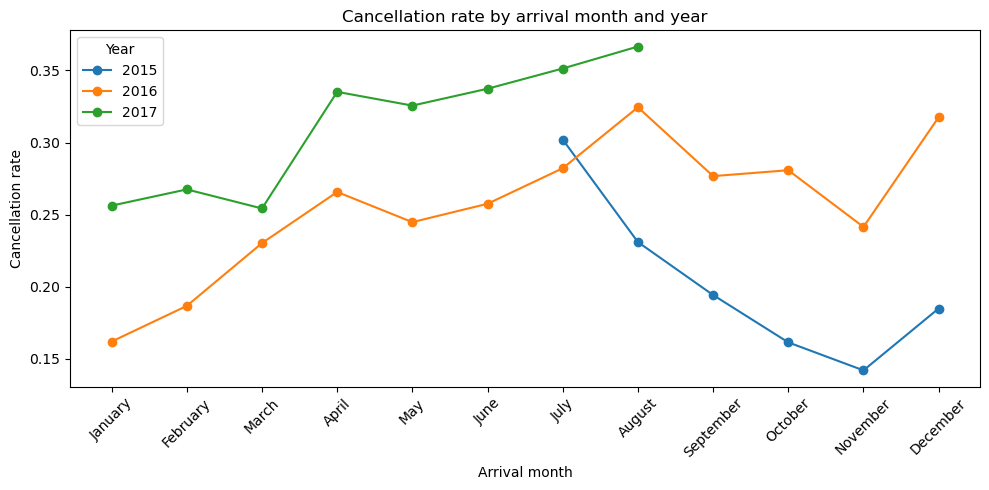

In [21]:
import matplotlib.pyplot as plt

months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]

rate = (df.groupby(["arrival_date_month", "arrival_date_year"])["is_canceled"]
          .mean()
          .unstack()
          .reindex(months))

rate.plot(marker="o", figsize=(10, 5))
plt.xticks(range(12), months, rotation=45)
plt.xlabel("Arrival month")
plt.ylabel("Cancellation rate")
plt.title("Cancellation rate by arrival month and year")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

  **Conclusions: cancellations over time**

  - The cancellation rate grows from year to year: about 20% in 2015 (July–December only), 26% in 2016 and 32% in 2017 (January–August only). In April–June 2017 about 33–34% of bookings were cancelled, against about 25–27% in the same months of 2016.
  - Across months the rate ranges from about 14% (November 2015) to about 37% (August 2017).
  - In 2016 and 2017 cancellations are lower in winter (January–March) and higher in summer (July–August), but the pattern is not the same every year: in autumn 2015 the rate fell from about 30% in July to about 14% in November.
  - Every month has at least 1,600 bookings, so these rates are not based on tiny groups.
  - The years are incomplete: 2015 has only July–December and 2017 only January–August, so months should only be compared across years where the lines overlap.
  - Because the cancellation rate shifts over time, the arrival month and year may help the model, and the train/test split should be done by time (older bookings for training, the latest for testing) rather than randomly.

In [22]:
df[(df['adults'] == 0) & (df['children']==0) & (df['babies']==0)].shape[0]

166

We need to remove rows witn no adults, children and babies

In [23]:
df = df.drop(
    df[
        (df['adults'] == 0) &
        (df['children'] == 0) &
        (df['babies'] == 0)
    ].index
)

In [24]:
df.shape

(86951, 29)

In [25]:
df.adr.describe()

count    86951.000000
mean       106.548511
std         54.923266
min         -6.380000
25%         72.250000
50%         98.280000
75%        134.100000
max       5400.000000
Name: adr, dtype: float64

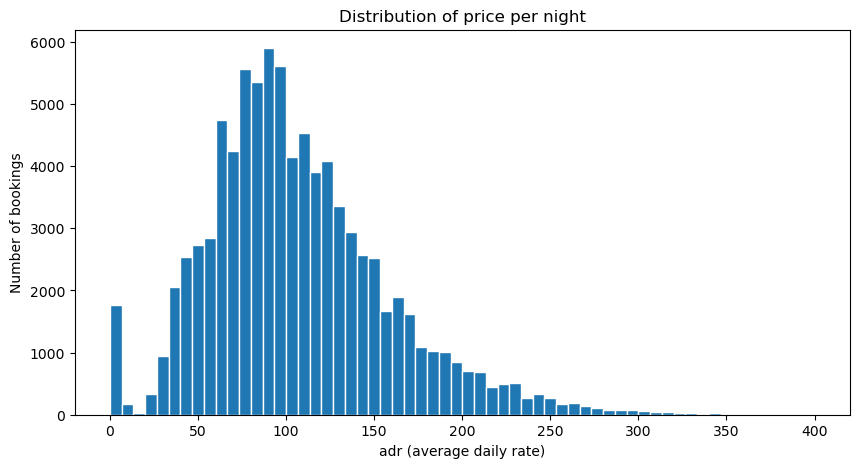

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["adr"], bins=60, range=(0, 400), edgecolor="white")
plt.xlabel("adr (average daily rate)")
plt.ylabel("Number of bookings")
plt.title("Distribution of price per night")
plt.show()

In [27]:
df.market_segment.value_counts()

market_segment
Online TA        51429
Offline TA/TO    13803
Direct           11771
Groups            4843
Corporate         4185
Complementary      692
Aviation           226
Undefined            2
Name: count, dtype: int64

In [28]:
zero = df[df['adr'] == 0]

print(len(zero) )                                        
print((zero['market_segment'] == 'Complementary').sum())  
print(zero['is_canceled'].mean())                         
print(df['is_canceled'].mean() )                          

1643
630
0.10286062081558126
0.27309634161769275


**Conclusions: price per night (adr)**

- The typical price is about 98 per night (median 98.3). Half of the bookings cost between about 72 and 134, and about 72% cost between 50 and 150. The mean (106.5) is higher than the median because of expensive bookings.
- The distribution is skewed to the right
- There is a separate bar at zero: 1,643 bookings have `adr = 0`. Part of them are complimentary rooms (630 in the "Complementary" segment), but the rest come from normal sales channels, so they may be data errors or special deals. Their cancellation rate is only about 10%, compared with about 27% overall, so they behave differently from the other bookings.
- Two clear outliers were removed: one booking with a negative price (-6.4) and one at 5,400 per night, while the next highest price was 510.

**Decision:** I keep the bookings with `adr = 0`, because many of them are real complimentary stays and their different cancellation rate carries information for the model. However I'll delete the outliers


In [29]:
df = df[(df['adr'] >= 0) & (df['adr'] < 1000)]

In [30]:
bins = [-1, 7, 30, 90, 180, 800]
labels = ["0-7 days", "8-30 days", "31-90 days", "91-180 days", "181+ days"]
df["lead_time_group"] = pd.cut(df["lead_time"], bins=bins, labels=labels)

df.groupby("lead_time_group", observed=True)["is_canceled"].agg(["count", "mean"])

,count,mean
lead_time_group,,
0-7 days,18195,0.084089
8-30 days,16296,0.252700
31-90 days,22633,0.318031
91-180 days,18143,0.347241
181+ days,11682,0.393683


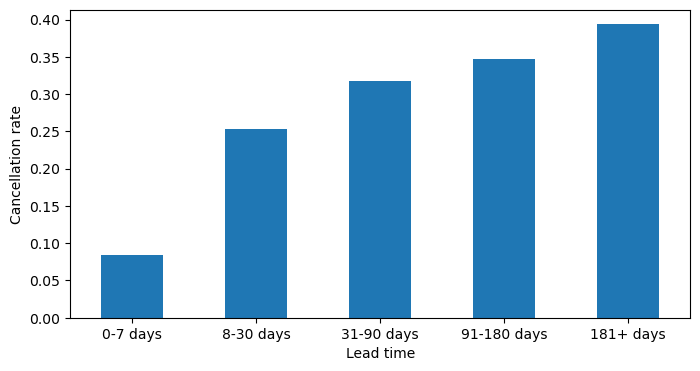

In [31]:
rate = df.groupby("lead_time_group", observed=True)["is_canceled"].mean()
rate.plot(kind="bar", rot=0, figsize=(8, 4))
plt.ylabel("Cancellation rate")
plt.xlabel("Lead time")
plt.show()

**Conclusions: lead time**

`lead_time` is the number of days between the booking and the arrival date (0 to 737 days). Bookings were grouped into five lead-time groups.

- The longer the lead time, the more often a booking is cancelled: about 8% for bookings made 0–7 days before arrival, 25% for 8–30 days, 32% for 31–90 days, 35% for 91–180 days and 39% for 181 days or more.
- The biggest jump is between last-minute bookings (0–7 days, 8% cancelled) and all the others. After about three months the increase becomes much smaller (32% → 35% → 39%).
- Every group contains at least 11,000 bookings, so these rates are reliable.
- `lead_time` is known at the moment of booking, so it can be used as a feature. It looks like one of the strongest predictors, but this is an association, not proof that a long lead time causes cancellations.

In [32]:
df.groupby('deposit_type')["is_canceled"].agg(["count", "mean"])

,count,mean
deposit_type,,
No Deposit,85826,0.265164
Non Refund,1016,0.945866
Refundable,107,0.242991


**Conclusions: deposit type**

- Almost all bookings (about 85,800) have no deposit, and about 26.5% of them were cancelled.
- Bookings with a non-refundable deposit are rare (about 1,000, around 1% of the data) but 94.6% of them were cancelled. This is surprising, because guests who lose their money when cancelling would be expected to cancel less.
- This group is unusual: it consists mostly of group bookings and travel agents/tour operators, almost all from Portugal, with a much longer lead time than other bookings (median 192 days vs 48). It is likely driven by specific partners and sales channels rather than by the deposit rule itself.
- Only about 100 bookings have a refundable deposit (24.3% cancelled), which is too few to draw conclusions.
- `deposit_type` is known at the moment of booking, so I keep it as a feature, but its strong effect should be interpreted with caution and may not generalise to other hotels.

In [33]:
df.market_segment.unique()

array(['Direct', 'Corporate', 'Online TA', 'Offline TA/TO',
       'Complementary', 'Groups', 'Undefined', 'Aviation'], dtype=object)

In [34]:
df.groupby('market_segment')["is_canceled"].agg(["count", "mean"])

,count,mean
market_segment,,
Aviation,226,0.199115
Complementary,692,0.122832
Corporate,4185,0.118996
Direct,11771,0.146801
Groups,4842,0.258984
Offline TA/TO,13802,0.145486
Online TA,51429,0.352428
Undefined,2,1.000000


**Conclusions: market segment**

- Online travel agents (Online TA) are the largest segment (about 59% of all bookings) and have the highest cancellation rate, 35.2%. It is the only large segment clearly above the overall average (about 27%).
- Corporate (11.9%), Complementary (12.3%), Offline TA/TO (14.5%) and Direct (14.7%) bookings are cancelled much less often. Aviation (19.9%) and Groups (25.9%) are in between.
- The "Undefined" segment has only 2 bookings, so its 100% cancellation rate is meaningless; these rows are removed.
- `market_segment` is known at the moment of booking and clearly separates low-risk and high-risk bookings, so it will be used as a feature.

In [35]:
df = df[~(df['market_segment']=='Undefined')]

In [36]:
pd.crosstab(df.market_segment, df.distribution_channel)

distribution_channel,Corporate,Direct,GDS,TA/TO,Undefined
market_segment,,,,,
Aviation,216,0,0,10,0
Complementary,78,539,0,75,0
Corporate,3879,153,0,153,0
Direct,81,11458,1,229,2
Groups,662,642,0,3538,0
Offline TA/TO,95,16,44,13647,0
Online TA,34,128,134,51132,1


**Conclusions: distribution channel**

- `distribution_channel` largely repeats `market_segment`: for most segments more than 90% of bookings come through the matching channel (e.g. 99% of "Online TA" and "Offline TA/TO" bookings come through the "TA/TO" channel, 97% of "Direct" bookings through "Direct").
- The "TA/TO" channel mixes online agents, offline agents and most group bookings (about 79% of all bookings), which `market_segment` separates into groups with very different cancellation rates (35%, 14.5% and 26%).
- Because `market_segment` is more detailed and the two columns overlap strongly, I drop `distribution_channel` and keep `market_segment`.

In [37]:
df = df.drop(columns='distribution_channel')

In [38]:
df["previous_cancellations_group"] = pd.cut(df["previous_cancellations"], bins=[-1, 0, 1, 100], labels=["0", "1", "2+"])
df["special_requests_group"] = pd.cut(df["total_of_special_requests"], bins=[-1, 0, 1, 2, 10], labels=["0", "1", "2", "3+"])

for col in ["is_repeated_guest", "previous_cancellations_group", "special_requests_group",
            "required_car_parking_spaces", "customer_type"]:
    print(col)
    print(df.groupby(col, observed=True)["is_canceled"].agg(["count", "mean"]).round(3))
    print()

is_repeated_guest
                   count   mean
is_repeated_guest              
0                  83585  0.281
1                   3362  0.077

previous_cancellations_group
                              count   mean
previous_cancellations_group              
0                             85290  0.265
1                              1381  0.757
2+                              276  0.264

special_requests_group
                        count   mean
special_requests_group              
0                       43560  0.329
1                       28945  0.224
2                       11772  0.212
3+                       2670  0.162

required_car_parking_spaces
                             count   mean
required_car_parking_spaces              
0                            79641  0.298
1                             7273  0.000
2                               28  0.000
3                                3  0.000
8                                2  0.000

customer_type
                 count   

**Conclusions: guest and booking characteristics**

- Repeat guests cancel much less often than new guests (7.7% vs 28.1%), although they are only about 4% of the bookings.
- The more special requests a guest makes, the less likely the booking is cancelled: 32.9% with no requests, 22.4% with one, 21.2% with two and 16.2% with three or more.
- Guests with exactly one previous cancellation cancel again in 75.7% of cases (1,381 bookings), compared with 26.5% for guests with none. For two or more previous cancellations the rate goes back to 26.4%, but this group is small (276 bookings), so no strong conclusion is drawn.
- Transient customers cancel most often (30.0%), while Transient-Party (14.3%), Contract (16.3%) and Group (9.8%, only 541 bookings) cancel less.
- None of the more than 7,000 bookings with a requested parking space was cancelled (0.0%, against 29.8% for bookings without). This is too perfect to be a real effect and likely means the field is only filled in for guests who actually arrived, so `required_car_parking_spaces` is treated as target leakage and is not used as a feature.

`assigned_room_type` and `booking_changes` are set after the booking is made (the room is assigned later and changes are counted until check-in or cancellation), so they would not be available when the prediction has to be made. Both columns are dropped.

In [39]:
df = df.drop(columns=['required_car_parking_spaces', 'lead_time_group',
                      'previous_cancellations_group', 'special_requests_group',
                      'assigned_room_type', 'booking_changes'])

In [40]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'is_repeated_guest',
       'previous_cancellations', 'previous_bookings_not_canceled',
       'reserved_room_type', 'deposit_type', 'days_in_waiting_list',
       'customer_type', 'adr', 'total_of_special_requests', 'has_agent'],
      dtype='object')

In [41]:
target = "is_canceled"
numerical = ["lead_time", "arrival_date_week_number", "arrival_date_day_of_month", "stays_in_weekend_nights",
             "stays_in_week_nights", "adults", "children", "babies", "is_repeated_guest", "previous_cancellations",
             "previous_bookings_not_canceled", "days_in_waiting_list", "adr", "total_of_special_requests", "has_agent"]

df[numerical].corrwith(df[target]).sort_values(key=abs, ascending=False)

lead_time                         0.182564
adr                               0.134242
has_agent                         0.133682
total_of_special_requests        -0.118870
is_repeated_guest                -0.088244
stays_in_week_nights              0.084716
adults                            0.080753
children                          0.068291
stays_in_weekend_nights           0.061427
previous_bookings_not_canceled   -0.051867
previous_cancellations            0.050943
babies                           -0.020595
arrival_date_day_of_month         0.005282
days_in_waiting_list              0.001854
arrival_date_week_number          0.001428
dtype: float64

In [42]:
from sklearn.metrics import mutual_info_score

categorical = ["hotel", "arrival_date_month", "meal", "country", "market_segment",
               "reserved_room_type", "deposit_type", "customer_type"]

df[categorical].apply(lambda s: mutual_info_score(s, df[target])).sort_values(ascending=False)

market_segment        0.026452
country               0.019406
deposit_type          0.012248
customer_type         0.009746
arrival_date_month    0.003757
hotel                 0.002621
meal                  0.002113
reserved_room_type    0.001639
dtype: float64

In [43]:
global_rate = df[target].mean()

def risk_table(col):
    g = df.groupby(col)[target].agg(["count", "mean"])
    g["diff"] = g["mean"] - global_rate
    g["risk"] = g["mean"] / global_rate
    return g

risk_table("market_segment")

,count,mean,diff,risk
market_segment,,,,
Aviation,226,0.199115,-0.073959,0.729160
Complementary,692,0.122832,-0.150242,0.449813
Corporate,4185,0.118996,-0.154078,0.435766
Direct,11771,0.146801,-0.126273,0.537588
Groups,4842,0.258984,-0.014091,0.948400
Offline TA/TO,13802,0.145486,-0.127588,0.532771
Online TA,51429,0.352428,0.079353,1.290592


In [44]:
risk_table("deposit_type")

,count,mean,diff,risk
deposit_type,,,,
No Deposit,85824,0.265147,-0.007927,0.970971
Non Refund,1016,0.945866,0.672792,3.463767
Refundable,107,0.242991,-0.030084,0.889833


In [45]:
risk_table("customer_type")

,count,mean,diff,risk
customer_type,,,,
Contract,3134,0.163050,-0.110024,0.597092
Group,541,0.097967,-0.175108,0.358755
Transient,71714,0.300151,0.027076,1.099153
Transient-Party,11558,0.143104,-0.129970,0.524049


In [46]:
risk_table("hotel")

,count,mean,diff,risk
hotel,,,,
City Hotel,53086,0.298666,0.025592,1.093718
Resort Hotel,33861,0.232952,-0.040122,0.853073


  ## EDA summary

  **Key findings**
  - After cleaning, 86947 bookings remain and 27.3% of them were cancelled.
  - Cancellations grow over time (20% → 26% → 32% by year).
  - Strongest signals: long lead time (8% for 0–7 days to 39% for 181+ days), Online TA segment (35%), no special requests, new guests.
  - Non-refundable deposits are almost always cancelled (95%), but this group is small and unusual.

## Feature importance analysis

The analysis is done on the whole cleaned dataset (before the train/test split), with the goal of deciding which features to keep for the models. The split by time is done afterwards.

**Numerical features (correlation with `is_canceled`)**
- The strongest are `lead_time` (0.18), `adr` (0.13), `has_agent` (0.13), `total_of_special_requests` (-0.12) and `is_repeated_guest` (-0.09).
- Next come `stays_in_week_nights` (0.08), `adults` (0.08), `children` (0.07), `stays_in_weekend_nights` (0.06), `previous_bookings_not_canceled` (-0.05) and `previous_cancellations` (0.05).
- `arrival_date_day_of_month` (0.005), `days_in_waiting_list` (0.002) and `arrival_date_week_number` (0.001) are practically uncorrelated with the target.
- Correlation only measures linear relations, so weak values do not always mean a useless feature (for example `previous_cancellations` has a non-monotonic effect).

**Categorical features (mutual information with `is_canceled`)**
- `market_segment` (0.026) and `country` (0.019) are the most informative, followed by `deposit_type` (0.012) and `customer_type` (0.010).
- `arrival_date_month` (0.004), `hotel` (0.003), `meal` (0.002) and `reserved_room_type` (0.002) carry little information.
- Mutual information is biased upwards for columns with many values such as `country`.

**Risk ratios (cancellation rate of a group divided by the overall rate)**
- Market segment: Online TA bookings are cancelled 1.29 times more often than average (35.2%), while Corporate (0.44), Complementary (0.45), Offline TA/TO (0.53) and Direct (0.54) are far below average.
- Deposit type: non-refundable bookings have a risk ratio of 3.46 (94.6% cancelled), but they are only about 1,000 bookings.
- Customer type: Transient customers cancel 1.10 times more often than average, Group customers only 0.36 times (541 bookings).
- Hotel: City Hotel 1.09 (29.9%), Resort Hotel 0.85 (23.3%).

**Decision**
- `arrival_date_week_number`, `arrival_date_day_of_month` and `days_in_waiting_list` are almost uncorrelated with the target, so they will not be used as features (the arrival date columns are still needed to split the data by time).
- All other columns are kept. The weak categorical features (`arrival_date_month`, `hotel`, `meal`, `reserved_room_type`) stay for now, and their usefulness will be checked again with the models.

  ## Modelling

In [47]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   

In [50]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

months = ["January","February","March","April","May","June","July","August","September","October","November","December"]
df["arrival_month_num"] = df["arrival_date_month"].map({m: i + 1 for i, m in enumerate(months)})
df["arrival_date"] = pd.to_datetime(dict(year=df["arrival_date_year"],
                                         month=df["arrival_month_num"],
                                         day=df["arrival_date_day_of_month"]))

df_full_train = df[df["arrival_date"] < "2017-06-01"].sort_values("arrival_date").reset_index(drop=True)
df_test = df[df["arrival_date"] >= "2017-06-01"].reset_index(drop=True)

country_counts = df_full_train["country"].value_counts()
frequent_countries = country_counts[country_counts >= 500].index
for d in (df_full_train, df_test):
    d["country"] = d["country"].where(d["country"].isin(frequent_countries), "other")

features = numerical + categorical   
X_full_train = df_full_train[features].to_dict(orient="records")
y_full_train = df_full_train["is_canceled"].values
X_test = df_test[features].to_dict(orient="records")
y_test = df_test["is_canceled"].values

cv = TimeSeriesSplit(n_splits=4)

baseline_dummy = Pipeline([("dv", DictVectorizer(sparse=False)), ("model", DummyClassifier(strategy="prior"))])
baseline_lr = Pipeline([("dv", DictVectorizer(sparse=False)), ("scaler", StandardScaler()),
                        ("model", LogisticRegression(max_iter=1000))])

for name, m in [("dummy", baseline_dummy), ("logistic regression, default parameters", baseline_lr)]:
    scores = cross_val_score(m, X_full_train, y_full_train, cv=cv, scoring="roc_auc")
    print(name, round(scores.mean(), 3), scores.round(3))

dummy 0.5 [0.5 0.5 0.5 0.5]
logistic regression, default parameters 0.76 [0.704 0.767 0.772 0.796]


In [51]:
# Logistic regression
pipe_lr = Pipeline([("dv", DictVectorizer(sparse=False)), ("scaler", StandardScaler()),
                    ("model", LogisticRegression(max_iter=1000))])
search_lr = GridSearchCV(pipe_lr, {"model__C": [0.01, 0.1, 1, 10]}, cv=cv, scoring="roc_auc", n_jobs=-1)

# Random forest
pipe_rf = Pipeline([("dv", DictVectorizer(sparse=False)), ("model", RandomForestClassifier(random_state=1, n_jobs=-1))])
grid_rf = {"model__n_estimators": [100, 200, 300], "model__max_depth": [5, 10, 15, 20, None],
           "model__min_samples_leaf": [1, 5, 10, 20], "model__max_features": ["sqrt", 0.3, 0.5]}
search_rf = RandomizedSearchCV(pipe_rf, grid_rf, n_iter=10, cv=cv, scoring="roc_auc", random_state=1, n_jobs=-1)

# Gradient boosting: random search
pipe_gb = Pipeline([("dv", DictVectorizer(sparse=False)), ("model", HistGradientBoostingClassifier(random_state=1))])
grid_gb = {"model__learning_rate": [0.03, 0.05, 0.1, 0.2], "model__max_depth": [3, 5, 7, None],
           "model__max_iter": [100, 200, 400], "model__min_samples_leaf": [20, 50, 100]}
search_gb = RandomizedSearchCV(pipe_gb, grid_gb, n_iter=10, cv=cv, scoring="roc_auc", random_state=1, n_jobs=-1)

results = {}
for name, search in [("logistic regression", search_lr), ("random forest", search_rf), ("gradient boosting", search_gb)]:
    search.fit(X_full_train, y_full_train)
    results[name] = search
    print(name, round(search.best_score_, 3), search.best_params_)

logistic regression 0.761 {'model__C': 0.01}
random forest 0.782 {'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 20}
gradient boosting 0.795 {'model__min_samples_leaf': 20, 'model__max_iter': 400, 'model__max_depth': 3, 'model__learning_rate': 0.05}


### Model comparison

| Model | Tuning | CV ROC AUC |
|---|---|---|
| Dummy (overall rate) | none | 0.500 |
| Logistic regression (baseline) | default parameters | 0.760 |
| Logistic regression | grid search (`C`) | 0.761 |
| Random forest | random search | 0.782 |
| Gradient boosting | random search | 0.795 |

Logistic regression with default parameters is the baseline. Tuning its regularisation barely changes the score (0.760 → 0.761), while gradient boosting improves the baseline by about 0.04 ROC AUC. Gradient boosting is therefore selected as the final model.

### Final evaluation and threshold choice

The model outputs the probability of cancellation, not a yes/no answer. To turn it into a decision, a threshold is needed: a booking is flagged as "likely to be cancelled" if its probability is above the threshold. The default threshold of 0.5 is not a good choice here, because only about a third of bookings are cancelled and the model rarely gives probabilities above 0.5, so many cancellations are missed.

For a hotel, a missed cancellation (an empty room that could have been resold) is usually more costly than a false alarm (for example, asking the guest for a deposit). Therefore the threshold is chosen as the highest value that still finds at least 70% of the cancellations (recall >= 0.70).

The threshold must not be chosen on the test set, otherwise the test result would be too optimistic. Instead, it is chosen on a validation period inside the training data (March-May 2017):
1. A copy of the best model (same hyperparameters, but untrained) is trained only on bookings before March 2017.
2. It predicts probabilities for March-May 2017, and the threshold is selected from the precision-recall curve.
3. The final model (trained on the full training data) is then evaluated on the test set once, with the default threshold of 0.5 and with the chosen threshold.

In [52]:
from sklearn.base import clone
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score)

best = results["gradient boosting"].best_estimator_


df_early = df_full_train[df_full_train["arrival_date"] < "2017-03-01"]
df_late = df_full_train[df_full_train["arrival_date"] >= "2017-03-01"]

model_v = clone(best)
model_v.fit(df_early[features].to_dict(orient="records"), df_early["is_canceled"].values)
proba_late = model_v.predict_proba(df_late[features].to_dict(orient="records"))[:, 1]
y_late = df_late["is_canceled"].values

precision, recall, thresholds = precision_recall_curve(y_late, proba_late)
ok = recall[:-1] >= 0.70            
threshold = thresholds[ok].max()    
print("chosen threshold:", round(threshold, 3))

proba_test = best.predict_proba(X_test)[:, 1]
print("test ROC AUC:", round(roc_auc_score(y_test, proba_test), 3))

for thr in [0.5, threshold]:
    pred = (proba_test >= thr).astype(int)
    print(f"threshold {thr:.3f}: precision {precision_score(y_test, pred):.3f}, "
          f"recall {recall_score(y_test, pred):.3f}, F1 {f1_score(y_test, pred):.3f}")
    print(confusion_matrix(y_test, pred))

chosen threshold: 0.226
test ROC AUC: 0.784
threshold 0.500: precision 0.640, recall 0.443, F1 0.524
[[7350 1152]
 [2573 2047]]
threshold 0.226: precision 0.549, recall 0.750, F1 0.634
[[5655 2847]
 [1155 3465]]


### Conclusions: test set evaluation

The final model (gradient boosting) was evaluated once on the test set (June-August 2017, 13,122 bookings, 35.2% cancelled). Its ROC AUC is 0.784, slightly lower than in cross-validation (0.795). This is expected: the test period is later than the training data and has a higher cancellation rate (about 25% in the training period), so the model has to work on a shifted distribution.

With the default threshold of 0.5, the model finds only 44% of the cancellations (precision 0.64, recall 0.44). With the chosen threshold of 0.226, it finds 75% of them (recall 0.75), with a precision of 0.55 and an F1 score of 0.63. In absolute numbers, about 3,500 cancellations are found and about 1,200 are missed, at the cost of about 2,800 false alarms.

So the lower threshold is a trade-off: the hotel catches many more cancellations but has to deal with more false alarms. The best threshold in practice depends on the real cost of each type of error.